<a href="https://colab.research.google.com/github/faisalalz171/Master-of-Research-COMP8990/blob/main/Distilling_Graph_Intelligence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Distilling Graph Intelligence for Urban Traffic Digital Twins Deployment

Supplementary code for the MRes thesis.

Faisal Al Zadjali

48366102

Macquarie University.

## Overview
This notebook contains the code and outputs behind the experiments reported in the thesis. It compares two graph neural network teachers (GCN+GRU and STGCN), a graph-free MLP+GRU trained without a teacher, and two graph-free students of the same architecture distilled from the teachers, on whole-network, one-step-ahead traffic-flow forecasting. The models are evaluated against a persistence baseline on accuracy, training time, model size, memory and inference latency in three cities of different size: Augsburg (420 sensors), Zurich (613) and Los Angeles (1,559). Each model receives the previous 12 intervals of flow and occupancy for every sensor and predicts the flow in the next interval. Predictions take a residual form, so an untrained model reproduces the persistence forecast.

## Data
The data are drawn from the Integrated Urban Traffic-Flood dataset (Lin et al., 2026), which builds on UTD19. The folder given by `DATA_DIR` in Section 1 must contain, for each city (`augsburg`, `zurich`, `losangeles`), the files `npz/{city}_data.npz`, `npz/{city}_meta.npz` and `npz/{city}_distance.csv`, together with `sensors/detectors_info.parquet`.

## Environment and reproducibility
All experiments were run on Google Colab with a Tesla T4 GPU (Python 3.13, PyTorch 2.11.0 with CUDA 13.0, PyTorch Geometric 2.8.0, NumPy 2.1.3 and pandas 2.2.3), using seeds 42, 43 and 44. Deterministic mode was not enabled. Repeating a run with the same seed gave identical results for the Plain MLP+GRU and a difference of about 0.0001 in test MAE for the GCN+GRU (Appendix A). The main experiment takes approximately 36 minutes per seed on this hardware. Completed runs are saved to Google Drive and skipped on re-execution.

## Contents
The table shows which notebook section produces each table, figure and result in the thesis.

| Notebook section | Output | Thesis |
|---|---|---|
| 2.1 Dataset overview | Dataset summary | Chapter 3 |
| 2.2 Pre-processing and splits | Windows per split | Chapter 3 |
| 2.3 Data quality checks | Timestamp, flow and occupancy checks | Chapter 3 |
| 2.4 Back-fill check | Leading gaps and back-filled values | Chapter 3 |
| 3.1 Models | Parameter counts | Chapter 4 |
| 3.2 Training, distillation and evaluation | Persistence baseline | Table 5.1 |
| 4.1 Main experiment | 45 trained models | Chapter 5 |
| 4.2 Latency, throughput, size and memory | Timing and memory measurements | Tables 5.4 and 5.5 |
| 5.1 Accuracy and training time | Test scores, training times | Tables 5.1 and 5.3 |
| 5.2 Derived comparisons | Student against teacher, accuracy cost | Tables 5.2 and 5.6 |
| 5.3 Best epoch and validation error | Best epochs, validation MSE | Section 5.1 |
| 5.4 Latency, throughput, size and memory | Latency, throughput, size, memory | Tables 5.4 and 5.5 |
| Appendix | Repeatability check, figures and further material | Section 4.1, Figures 5.1 and 5.2 |

## 1. Setup and reproducibility
Mounts Google Drive, installs the graph library, and sets the paths, seeds and hyperparameters used throughout. Results are written to `RESULTS_DIR` on Drive. The last lines print the software and hardware versions and check that the data files exist.

In [2]:

from google.colab import drive
drive.mount('/content/drive')

!pip install -q torch_geometric

DATA_DIR    = "/content/drive/MyDrive"

import os, sys, json, random, time, platform
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import torch_geometric
from torch_geometric.nn import GCNConv
from torch_geometric.utils import dense_to_sparse
import matplotlib.pyplot as plt
from IPython.display import display

# ── Configuration (every setting in one place) ───────────────────────────────
DATA_DIR    = "/content/drive/MyDrive"               # the folder that holds augsburg/, zurich/, losangeles/
RESULTS_DIR = "/content/drive/MyDrive/mres_results"  # results are saved to Drive, so a disconnect loses nothing
SEEDS       = [42, 43, 44]                                  # one seed for now; e.g. [42, 43, 44] for mean ± std

IN_STEPS, HIDDEN, EPOCHS, BATCH_SIZE, LR = 12, 32, 30, 32, 1e-3
KD_LAMBDA1, KD_LAMBDA2 = 10.0, 1.0                   # weights of the KL and contrastive terms

CITIES = {
    "Augsburg":    {"folder": "augsburg",   "size": "small"},
    "Zurich":      {"folder": "zurich",     "size": "medium"},
    "Los Angeles": {"folder": "losangeles", "size": "large"},
}
os.makedirs(RESULTS_DIR, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEEDS[0])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ── Environment record ───────────────────────────────────────────────────────
print(f"Python         : {sys.version.split()[0]} on {platform.system()}")
print(f"PyTorch        : {torch.__version__}")
print(f"PyG            : {torch_geometric.__version__}")
print(f"NumPy / pandas : {np.__version__} / {pd.__version__}")
print(f"Device         : {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))
print(f"Seeds          : {SEEDS}")

# ── Check that the expected data files exist ─────────────────────────────────
required = ["npz/{c}_data.npz", "npz/{c}_meta.npz", "npz/{c}_distance.csv", "sensors/detectors_info.parquet"]
for name, info in CITIES.items():
    c = info["folder"]
    missing = [p.format(c=c) for p in required if not os.path.exists(os.path.join(DATA_DIR, c, p.format(c=c)))]
    print(f"{name:<12} {'OK' if not missing else 'MISSING ' + str(missing)}")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 35.8 MB/s eta 0:00:00
Python         : 3.13.15 on Linux
PyTorch        : 2.11.0+cu130
PyG            : 2.8.1
NumPy / pandas : 2.1.3 / 2.2.3
Device         : cuda (Tesla T4)
Seeds          : [42, 43, 44]
Augsburg     OK
Zurich       OK
Los Angeles  OK


In [3]:
import glob
DISPLAY = {"Plain MLP": "Plain MLP+GRU", "KD<-GCN+GRU": "Student ← GCN+GRU", "KD<-STGCN": "Student ← STGCN"}
dn = lambda m: DISPLAY.get(m, m)

## 2. Data
The cells in this section describe the data, prepare it for modelling and check its quality.

### 2.1 Dataset overview
For each city, the sensor readings and metadata are loaded and ordered by time. The outage rule is then applied: the series is truncated at the first day on which more than half of the flow readings are missing. The table summarises the data retained, including the number of sensors, the recording period and sampling interval, the share of missing flow readings, the number of sensors with no readings at all, and the road graph (undirected edges, average degree and share of isolated sensors). The summary is saved to `dataset_summary.csv`.

In [4]:
rows = []
for name, info in CITIES.items():
    c = info["folder"]; base = os.path.join(DATA_DIR, c)
    meta = np.load(os.path.join(base, "npz", f"{c}_meta.npz"), allow_pickle=True)
    data = np.load(os.path.join(base, "npz", f"{c}_data.npz"), allow_pickle=True)["data"]
    det  = pd.read_parquet(os.path.join(base, "sensors", "detectors_info.parquet"))
    dist = pd.read_csv(os.path.join(base, "npz", f"{c}_distance.csv"), index_col=0)

    ts = pd.to_datetime(meta["timestamps"], dayfirst=True)
    order = np.argsort(ts.values); ts = ts[order]
    sid = meta["sensor_road_ids"]
    flow = data[:, sid, 0][order]                       # slice sensors first: the full array is large
    del data
    res = int(round(pd.Series(ts).diff().dt.total_seconds().median() / 60))

    # outage rule: cut at the first day with more than 50% of flow missing
    daily = pd.Series(np.isnan(flow).mean(axis=1), index=ts).groupby(ts.date).mean()
    bad = daily[daily > 0.5]
    cut = bad.index.min() if len(bad) else None
    keep = np.array([d < cut for d in ts.date]) if cut is not None else np.ones(len(ts), bool)
    ts_u, flow_u = ts[keep], flow[keep]
    days_u = sorted(set(ts_u.date))

    # graph among sensors (undirected pairs, self-loops excluded)
    e = dist.reset_index(); e.columns = ["a", "b", "d"]
    sset = set(sid.tolist())
    e = e[e["a"].isin(sset) & e["b"].isin(sset) & (e["a"] != e["b"])]
    pairs = {tuple(sorted(p)) for p in zip(e["a"], e["b"])}
    deg = pd.Series([x for p in pairs for x in p]).value_counts()

    rows.append({
        "City": name, "Size": info["size"], "Sensors used": len(sid), "Detectors in file": len(det),
        "Resolution (min)": res,
        "Days in file": len(set(ts.date)), "Days used": len(days_u),
        "Contiguous": "yes" if all((days_u[i+1] - days_u[i]).days == 1 for i in range(len(days_u) - 1)) else "no",
        "From": ts_u.min().date(), "To": ts_u.max().date(),
        "Timesteps used": len(ts_u), "Flow missing, used data (%)": round(100 * np.isnan(flow_u).mean(), 1),
        "Dead sensors": int(np.isnan(flow_u).all(axis=0).sum()),
        "Edges": len(pairs), "Avg degree": round(2 * len(pairs) / len(sid), 2),
        "Isolated sensors (%)": round(100 * (len(sid) - len(deg)) / len(sid), 1),
    })

dataset_summary = pd.DataFrame(rows).set_index("City")
dataset_summary.to_csv(os.path.join(RESULTS_DIR, "dataset_summary.csv"))
print("Table 2. Dataset summary (after the outage rule)")
display(dataset_summary.T)

Table 2. Dataset summary (after the outage rule)


City,Augsburg,Zurich,Los Angeles
Size,small,medium,large
Sensors used,420,613,1559
Detectors in file,717,1020,1725
Resolution (min),5,3,3
Days in file,20,7,6
Days used,16,7,6
Contiguous,yes,yes,no
From,2017-05-06,2015-10-26,2017-10-02
To,2017-05-21,2015-11-01,2017-10-10
Timesteps used,4608,3359,2879


### 2.2 Pre-processing and splits
The following steps are applied to each city in turn.

1. **Time order.** Observations are sorted by parsed timestamp, because the stored order is not reliable.
2. **Outage rule.** The series is truncated at the first day on which more than half of the flow readings are missing.
3. **Missing values.** Missing flow and occupancy values are filled by carrying the last reading forward, then the next reading backward, with any remaining gaps set to zero. A mask of the observed flow values is kept, and it is used for validation and testing so that filled values are never scored.
4. **Graph.** Sensors are linked through the pairwise distance file. Edge weights follow a Gaussian kernel of the distance, exp(−d²/σ²), where σ is the standard deviation of the distances, and every sensor has a self-loop of weight 1.
5. **Windows.** Each sample consists of 12 consecutive intervals of flow and occupancy for every sensor, and the target is the flow in the following interval. Windows that span a recording gap are dropped.
6. **Split.** Windows are divided chronologically into 70% training, 15% validation and 15% test.
7. **Normalisation.** Flow and occupancy are standardised using the mean and standard deviation of the training period only.

The table lists, for each city and split, the number of windows, the number dropped because of a recording gap, the first and last target time, and the share of missing targets. It is saved to `splits.csv`.

In [4]:
class WindowDataset(Dataset):
    """Lazy windows: input = 12 steps of (flow, occ); target = next-step flow; mask = observed targets."""
    def __init__(self, X, mask, starts):
        self.X, self.mask, self.starts = X, mask, starts
    def __len__(self):
        return len(self.starts)
    def __getitem__(self, k):
        t = int(self.starts[k])
        return self.X[t:t + IN_STEPS], self.X[t + IN_STEPS, :, 0], self.mask[t + IN_STEPS]


def build_city(name):
    c = CITIES[name]["folder"]
    base = os.path.join(DATA_DIR, c)
    meta = np.load(os.path.join(base, "npz", f"{c}_meta.npz"), allow_pickle=True)
    raw  = np.load(os.path.join(base, "npz", f"{c}_data.npz"), allow_pickle=True)["data"]
    dist = pd.read_csv(os.path.join(base, "npz", f"{c}_distance.csv"), index_col=0)

    # 1. Time order: sort by parsed datetime (the stored order can be wrong)
    ts = pd.to_datetime(meta["timestamps"], dayfirst=True)
    order = np.argsort(ts.values)
    ts = ts[order]
    sid = meta["sensor_road_ids"]
    sensor = raw[:, sid, :][order]            # slice sensors first: raw array is large
    del raw
    flow, occ = sensor[:, :, 0], sensor[:, :, 2]
    res = pd.Series(ts).diff().dt.total_seconds().median()

    # 2. Outage rule: truncate at the first day with more than 50% of flow missing
    daily = pd.Series(np.isnan(flow).mean(axis=1), index=ts).groupby(ts.date).mean()
    bad = daily[daily > 0.5]
    cut_day = bad.index.min() if len(bad) else None
    if cut_day is not None:
        keep = np.array([d < cut_day for d in ts.date])
        ts, flow, occ = ts[keep], flow[keep], occ[keep]

    # 3. Fill missing values and keep a mask of observed flow
    mask = ~np.isnan(flow)
    fill = lambda a: pd.DataFrame(a).ffill(axis=0).bfill(axis=0).fillna(0).values
    X = np.stack([fill(flow), fill(occ)], axis=-1).astype(np.float32)
    T, N = flow.shape

    # 4. Graph among sensor road segments
    idx = {r: i for i, r in enumerate(sid)}
    e = dist.reset_index(); e.columns = ["a", "b", "d"]
    sset = set(sid.tolist())
    e = e[e["a"].isin(sset) & e["b"].isin(sset)]
    sigma = e["d"].std()
    i, j = e["a"].map(idx).to_numpy(), e["b"].map(idx).to_numpy()
    w = np.exp(-(e["d"].to_numpy() ** 2) / sigma ** 2)
    A = np.zeros((N, N), dtype=np.float32)
    A[i, j] = w; A[j, i] = w
    np.fill_diagonal(A, 1.0)
    edge_index, edge_weight = dense_to_sparse(torch.from_numpy(A))

    # 5-6. Windows and chronological split; drop windows that span a recording gap
    Nw = T - IN_STEPS
    tr_end, va_end = int(0.70 * Nw), int(0.85 * Nw)
    gap = (np.diff(ts.values).astype("timedelta64[s]").astype(np.float64) > 1.5 * res).astype(int)
    cs = np.concatenate([[0], np.cumsum(gap)])
    crosses = (cs[np.arange(Nw) + IN_STEPS] - cs[np.arange(Nw)]) > 0
    bounds = {"train": (0, tr_end), "val": (tr_end, va_end), "test": (va_end, Nw)}
    starts  = {k: np.array([t for t in range(a, b) if not crosses[t]]) for k, (a, b) in bounds.items()}
    dropped = {k: int(crosses[a:b].sum()) for k, (a, b) in bounds.items()}

    # 7. Normalise with training-period statistics only
    mu = X[:tr_end + IN_STEPS].mean(axis=(0, 1), keepdims=True)
    sd = X[:tr_end + IN_STEPS].std(axis=(0, 1), keepdims=True); sd[sd == 0] = 1
    Xn = (X - mu) / sd

    return {
        "name": name, "ts": ts, "res_min": res / 60, "T": T, "N": N, "cut_day": cut_day,
        "X": torch.from_numpy(Xn), "mask": torch.from_numpy(mask),
        "flow_mean": float(mu[0, 0, 0]), "flow_std": float(sd[0, 0, 0]),
        "A": A, "edge_index": edge_index, "edge_weight": edge_weight,
        "sensor_road_ids": sid, "starts": starts, "dropped": dropped,
    }


DATA = {name: build_city(name) for name in CITIES}

# ── Table 3: periods, sizes and missing share per split ──────────────────────
rows = []
for name, d in DATA.items():
    for split in ["train", "val", "test"]:
        tgt = d["starts"][split] + IN_STEPS
        rows.append({
            "City": name, "Split": split,
            "Windows": len(tgt), "Dropped (gap)": d["dropped"][split],
            "First target": d["ts"][tgt[0]].strftime("%Y-%m-%d %H:%M (%a)"),
            "Last target":  d["ts"][tgt[-1]].strftime("%Y-%m-%d %H:%M (%a)"),
            "Targets missing (%)": round(100 * (1 - d["mask"].numpy()[tgt].mean()), 1),
        })
splits_table = pd.DataFrame(rows).set_index(["City", "Split"])
splits_table.to_csv(os.path.join(RESULTS_DIR, "splits.csv"))

for name, d in DATA.items():
    cut = f", cut at {d['cut_day']}" if d["cut_day"] is not None else ", no cut"
    print(f"{name:<12} {d['T']} steps x {d['N']} sensors{cut}, {d['res_min']:.0f}-min resolution")
print("\nTable 3. Training, validation and test periods")
display(splits_table)

Augsburg     4608 steps x 420 sensors, cut at 2017-05-22, 5-min resolution
Zurich       3359 steps x 613 sensors, no cut, 3-min resolution
Los Angeles  2879 steps x 1559 sensors, no cut, 3-min resolution

Table 3. Training, validation and test periods


Windows  Dropped (gap)            First target  \
City        Split                                                   
Augsburg    train     3217              0  2017-05-06 01:00 (Sat)   
            val        689              0  2017-05-17 05:05 (Wed)   
            test       690              0  2017-05-19 14:30 (Fri)   
Zurich      train     2342              0  2015-10-26 00:39 (Mon)   
            val        502              0  2015-10-30 21:45 (Fri)   
            test       503              0  2015-10-31 22:51 (Sat)   
Los Angeles train     1982             24  2017-10-02 00:36 (Mon)   
            val        418             12  2017-10-09 04:54 (Mon)   
            test       431              0  2017-10-10 02:27 (Tue)   

                              Last target  Targets missing (%)  
City        Split                                               
Augsburg    train  2017-05-17 05:00 (Wed)                  7.6  
            val    2017-05-19 14:25 (Fri)                  6.9  
            test   2017-05-21 23:55 (Sun)                  7.2  
Zurich      train  2015-10-30 21:42 (Fri)                  0.0  
            val    2015-10-31 22:48 (Sat)                  0.0  
            test   2015-11-01 23:57 (Sun)                  0.0  
Los Angeles train  2017-10-09 04:51 (Mon)                  6.6  
            val    2017-10-10 02:24 (Tue)                  9.2  
            test   2017-10-10 23:57 (Tue)                  7.8

### 2.3 Data quality checks
Before modelling, the prepared data were checked for timestamp problems, implausible values and graph consistency. The first cell reports duplicate timestamps, irregular sampling intervals, ambiguous or non-existent local times, the UTC offset, and the hours of lowest and highest mean flow as a plausibility check. It also reports the mean and median flow, the mean and maximum occupancy, the share of test targets of one vehicle or fewer, the number of undirected edges, and the hardware recorded in the saved result files. The second cell counts occupancy values above 1 in each city; these values are reported and not corrected.

In [4]:
MAIN_DIR = os.path.join(RESULTS_DIR, "main")
import glob
TZ = {"Augsburg": "Europe/Berlin", "Zurich": "Europe/Zurich", "Los Angeles": "America/Los_Angeles"}

def raw_used(city):
    c = CITIES[city]["folder"]; base = os.path.join(DATA_DIR, c)
    meta = np.load(os.path.join(base, "npz", f"{c}_meta.npz"), allow_pickle=True)
    raw = np.load(os.path.join(base, "npz", f"{c}_data.npz"), allow_pickle=True)["data"]
    ts = pd.to_datetime(meta["timestamps"], dayfirst=True)
    s = raw[:, meta["sensor_road_ids"], :][np.argsort(ts.values)]; del raw
    T = DATA[city]["T"]                       # the outage cut keeps the first T sorted rows
    return s[:T, :, 0], s[:T, :, 2]           # flow, occupancy

print("1. Timestamps")
for city, d in DATA.items():
    ts, res = d["ts"], d["res_min"]
    steps = pd.Series(ts).diff().dropna().dt.total_seconds() / 60
    odd = steps[steps != res].round(1).value_counts().head(4).to_dict()
    loc = ts.tz_localize(TZ[city], ambiguous="NaT", nonexistent="NaT")
    offs = sorted({str(t.utcoffset()) for t in loc.dropna()})
    flow = np.where(d["mask"].numpy(), d["X"][:, :, 0].numpy() * d["flow_std"] + d["flow_mean"], np.nan)
    prof = pd.Series(np.nanmean(flow, axis=1), index=ts).groupby(ts.hour).mean()
    print(f"  {city:<12} duplicates {ts.duplicated().sum()} | irregular steps {odd} | "
          f"nonexistent/ambiguous local times {int(loc.isna().sum())} | UTC offsets {offs} | "
          f"lowest-flow hour {prof.idxmin()}, highest {list(prof.nlargest(2).index)}")

print("\n9-11. Flow level, occupancy, MAPE exclusion, edges")
rows = []
for city, d in DATA.items():
    flow, occ = raw_used(city)
    tgt = d["starts"]["test"] + IN_STEPS
    ft = flow[tgt]; obs = ~np.isnan(ft)
    A = d["A"]; N = len(A); und = int(((A > 0).sum() - N) // 2)
    rows.append({"City": city, "Flow mean": np.nanmean(flow), "Flow median": np.nanmedian(flow),
                 "Occupancy mean": np.nanmean(occ), "Occupancy max": np.nanmax(occ),
                 "Test targets <= 1 vehicle (%)": 100 * ((ft <= 1) & obs).sum() / obs.sum(),
                 "Undirected edges": und, "Directed entries": 2 * und})
display(pd.DataFrame(rows).set_index("City").round(2))

print("\n4. Devices recorded in the saved result files")
dev_count = {}
for f in glob.glob(os.path.join(MAIN_DIR, "*.json")):
    k = json.load(open(f)).get("device"); dev_count[k] = dev_count.get(k, 0) + 1
print(dev_count)
!nvidia-smi --query-gpu=name,driver_version,memory.total --format=csv
!lscpu | grep "Model name"

1. Timestamps
  Augsburg     duplicates 0 | irregular steps {} | nonexistent/ambiguous local times 0 | UTC offsets ['2:00:00'] | lowest-flow hour 3, highest [17, 16]
  Zurich       duplicates 0 | irregular steps {} | nonexistent/ambiguous local times 0 | UTC offsets ['1:00:00'] | lowest-flow hour 3, highest [17, 16]
  Los Angeles  duplicates 0 | irregular steps {1443.0: 1, 2883.0: 1, 6.0: 1} | nonexistent/ambiguous local times 0 | UTC offsets ['-1 day, 17:00:00'] | lowest-flow hour 4, highest [17, 18]

9-11. Flow level, occupancy, MAPE exclusion, edges


,Flow mean,Flow median,Occupancy mean,Occupancy max,Test targets <= 1 vehicle (%),Undirected edges,Directed entries
City,,,,,,,
Augsburg,169.130005,92.000000,0.13,1.22,14.25,125,250
Zurich,200.190002,140.000000,0.10,28.34,10.05,218,436
Los Angeles,830.559998,715.099976,0.06,0.96,0.03,442,884



4. Devices recorded in the saved result files
{'Tesla T4': 45}
name, driver_version, memory.total [MiB]
Tesla T4, 580.82.07, 15360 MiB
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz


In [5]:
for city in CITIES:
    _, occ = raw_used(city)
    o = occ[~np.isnan(occ)]
    print(f"{city:<12} occupancy > 1: {(o > 1).sum():,} of {o.size:,} ({100 * (o > 1).mean():.3f}%) | "
          f"99.9th percentile {np.percentile(o, 99.9):.2f}")

Augsburg     occupancy > 1: 15 of 1,791,143 (0.001%) | 99.9th percentile 1.00
Zurich       occupancy > 1: 3,188 of 2,059,067 (0.155%) | 99.9th percentile 1.05
Los Angeles  occupancy > 1: 0 of 4,166,572 (0.000%) | 99.9th percentile 0.62


### 2.4 Back-fill check
Back-filling copies a sensor's first reading to the earlier rows that are missing. This would leak information from the validation or test periods into the training data if a sensor's first reading came after the training boundary. The cell therefore reports, for each city, the number of sensors whose series begins with a gap, the number of back-filled values in the training period and their share of all training values, and the number of sensors whose first reading falls after the training boundary.

In [6]:
print(f"{'City':<12}{'leading-gap sensors':>20}{'back-filled train values':>26}{'share':>9}{'first reading after train boundary':>38}")
for city, info in CITIES.items():
    c = info["folder"]; base = os.path.join(DATA_DIR, c, "npz")
    meta = np.load(os.path.join(base, f"{c}_meta.npz"), allow_pickle=True)
    raw = np.load(os.path.join(base, f"{c}_data.npz"), allow_pickle=True)["data"]
    ts = pd.to_datetime(meta["timestamps"], dayfirst=True)
    flow = raw[:, meta["sensor_road_ids"], 0][np.argsort(ts.values)]; del raw
    flow = flow[:DATA[city]["T"]]                         # same outage cut as the experiments
    Nw = DATA[city]["T"] - IN_STEPS
    train_end = int(0.70 * Nw) + IN_STEPS                 # rows used for training and statistics
    obs = ~np.isnan(flow)
    first = np.where(obs.any(0), obs.argmax(0), -1)       # first observed row (-1 = dead sensor)
    lead = first[first > 0]
    late = int((first >= train_end).sum())
    back = int(np.minimum(lead, train_end).sum())
    print(f"{city:<12}{len(lead):>20}{back:>26,}{100 * back / (train_end * flow.shape[1]):>8.2f}%{late:>38}")
print("Expected: 8 / 0 / 584 leading-gap sensors; 12,402 (0.91%) / 0 / 28,992 (0.92%); 0 after the boundary.")

City         leading-gap sensors  back-filled train values    share    first reading after train boundary
Augsburg                       8                    12,402    0.91%                                     0
Zurich                         0                         0    0.00%                                     0
Los Angeles                  584                    28,992    0.92%                                     0
Expected: 8 / 0 / 584 leading-gap sensors; 12,402 (0.91%) / 0 / 28,992 (0.92%); 0 after the boundary.


## 3. Methodology

### 3.1 Models
Five models are defined. The two teachers are graph neural networks. The GCN+GRU applies a graph convolution to the sensors at every time step and then a GRU over time. The STGCN stacks two spatio-temporal blocks, each consisting of a gated temporal convolution, a graph convolution and a second gated temporal convolution, followed by batch normalisation and two linear layers. The graph-free MLP+GRU applies a linear projection and three linear layers with ReLU to each sensor separately, followed by a GRU over time. It uses no graph, and it serves both as the baseline trained without a teacher and as the architecture of the two students. All models have a hidden width of 32.

Every model predicts the last observed reading plus a learned change, and the output layer is initialised at zero, so an untrained model reproduces the persistence forecast. Each model also returns an embedding, the final hidden state of each sensor, which is used by the contrastive term of the distillation loss. The cell prints the parameter counts, which should be 6,465 (GCN+GRU), 25,473 (STGCN) and 9,633 (MLP+GRU). The list `MODELS` pairs each model with the teacher it is distilled from, if any.

In [5]:
def batched_graph(edge_index, edge_weight, B, N):
    offs = (torch.arange(B, device=edge_index.device) * N).view(B, 1, 1)
    ei = (edge_index.unsqueeze(0) + offs).permute(1, 0, 2).reshape(2, -1)
    return ei, edge_weight.repeat(B)

class GCNGRU(nn.Module):
    """Teacher 1: graph convolution at each timestep, then a GRU over time."""
    def __init__(self, in_dim, hidden):
        super().__init__()
        self.gcn = GCNConv(in_dim, hidden)
        self.gru = nn.GRU(hidden, hidden, batch_first=True)
        self.dropout = nn.Dropout(0.1)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x, edge_index, edge_weight):
        B, T, N, F_ = x.shape
        ei, ew = batched_graph(edge_index, edge_weight, B, N)
        h = torch.stack([torch.relu(self.gcn(x[:, t].reshape(B * N, F_), ei, ew)).reshape(B, N, -1)
                         for t in range(T)], dim=1)
        seq = self.dropout(h.permute(0, 2, 1, 3).reshape(B * N, T, -1))
        last = self.gru(seq)[0][:, -1]
        return self.fc(last).reshape(B, N), last.reshape(B, N, -1)

class STConvBlock(nn.Module):
    def __init__(self, in_c, hidden, out_c, kernel=3):
        super().__init__()
        self.t1 = nn.Conv2d(in_c, 2 * hidden, (1, kernel))
        self.gcn = GCNConv(hidden, hidden)
        self.t2 = nn.Conv2d(hidden, 2 * out_c, (1, kernel))
        self.bn = nn.BatchNorm2d(out_c)
    def forward(self, x, ei, ew):
        x = F.glu(self.t1(x), dim=1)
        B, C, N, T = x.shape
        x = torch.stack([torch.relu(self.gcn(x[..., t].permute(0, 2, 1).reshape(B * N, C), ei, ew)).reshape(B, N, C)
                         for t in range(T)], dim=-1).permute(0, 2, 1, 3)
        return self.bn(F.glu(self.t2(x), dim=1))

class STGCN(nn.Module):
    """Teacher 2: same graph, time modelled with convolutions instead of a GRU."""
    def __init__(self, in_dim, hidden, in_steps):
        super().__init__()
        self.b1 = STConvBlock(in_dim, hidden, hidden)
        self.b2 = STConvBlock(hidden, hidden, hidden)
        self.fc = nn.Linear(hidden * (in_steps - 8), hidden)
        self.out = nn.Linear(hidden, 1)
    def forward(self, x, edge_index, edge_weight):
        B, T, N, F_ = x.shape
        ei, ew = batched_graph(edge_index, edge_weight, B, N)
        x = self.b2(self.b1(x.permute(0, 3, 2, 1), ei, ew), ei, ew)
        emb = self.fc(x.permute(0, 2, 1, 3).reshape(B, N, -1))
        return self.out(emb).squeeze(-1), emb

class StudentMLP(nn.Module):
    """Student and graph-free baseline: an MLP per sensor, then a GRU. No graph input."""
    def __init__(self, in_dim, hidden, mlp_layers=3):
        super().__init__()
        self.proj = nn.Linear(in_dim, hidden)
        self.mlp = nn.Sequential(*[m for _ in range(mlp_layers) for m in (nn.Linear(hidden, hidden), nn.ReLU())])
        self.gru = nn.GRU(hidden, hidden, batch_first=True)
        self.dropout = nn.Dropout(0.1)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        B, T, N, F_ = x.shape
        h = self.mlp(self.proj(x))
        seq = self.dropout(h.permute(0, 2, 1, 3).reshape(B * N, T, -1))
        last = self.gru(seq)[0][:, -1]
        return self.fc(last).reshape(B, N), last.reshape(B, N, -1)

class Residual(nn.Module):
    """prediction = last observed reading + learned change. Output layer starts at zero,
    so an untrained model equals the persistence forecast."""
    def __init__(self, base, out_layer):
        super().__init__()
        self.base = base
        nn.init.zeros_(out_layer.weight); nn.init.zeros_(out_layer.bias)
    def forward(self, x, *graph):
        pred, emb = self.base(x, *graph)
        return x[:, -1, :, 0] + pred, emb

IN_DIM = 2
def res_gcngru():  b = GCNGRU(IN_DIM, HIDDEN);          return Residual(b, b.fc)
def res_stgcn():   b = STGCN(IN_DIM, HIDDEN, IN_STEPS); return Residual(b, b.out)
def res_student(): b = StudentMLP(IN_DIM, HIDDEN);      return Residual(b, b.fc)

MODELS = [  # name, builder, needs_graph, teacher name (None for plain training)
    ("GCN+GRU",     res_gcngru,  True,  None),
    ("STGCN",       res_stgcn,   True,  None),
    ("Plain MLP",   res_student, False, None),
    ("KD<-GCN+GRU", res_student, False, "GCN+GRU"),
    ("KD<-STGCN",   res_student, False, "STGCN"),
]
NEEDS_GRAPH = {m[0]: m[2] for m in MODELS}
def n_params(m): return sum(p.numel() for p in m.parameters())

for name, build, g, _ in MODELS[:3]:
    print(f"{name:<10} params {n_params(build()):>7,}")   # expect 6,465 / 25,473 / 9,633

GCN+GRU    params   6,465
STGCN      params  25,473
Plain MLP  params   9,633


### 3.2 Training, distillation and evaluation
Models are trained with Adam (learning rate 10⁻³, halved every 10 epochs), a batch size of 32, 30 epochs and gradient clipping at 1.0. After each epoch the validation mean squared error is computed on observed targets only, and the weights from the epoch with the lowest validation error are restored.

For distillation, the student minimises the sum of the mean squared error, a KL-divergence term and a contrastive-style term on the embeddings, weighted by λ₁ = 10 and λ₂ = 1. The KL term compares the softmax of the teacher's and the student's predictions across sensors, and the contrastive term uses a temperature of 0.05. The teacher is trained first and then frozen: it is placed in evaluation mode, and its parameters receive no gradients.

For evaluation, predictions are converted back to vehicles per interval and scored on observed test targets only (MAE, RMSE, and MAPE on targets above one vehicle). The same cell computes the persistence baseline, which repeats the last observed flow, and saves it to `persistence_baseline.json`.

In [6]:
def run(model, xb, d, needs_graph):
    return model(xb, d["ei"], d["ew"]) if needs_graph else model(xb)

for d in DATA.values():
    d["ei"], d["ew"] = d["edge_index"].to(device), d["edge_weight"].to(device)

def make_loader(d, split, shuffle, seed=None):
    g = torch.Generator().manual_seed(seed) if seed is not None else None
    return DataLoader(WindowDataset(d["X"], d["mask"], d["starts"][split]),
                      batch_size=BATCH_SIZE, shuffle=shuffle, generator=g)

def masked_mse(pred, target, mask):
    m = mask.float()
    return (((pred - target) ** 2) * m).sum() / m.sum().clamp(min=1)

def loss_kl(s_pred, t_pred):
    """KL divergence between the softmax of student and teacher predictions across sensors."""
    return F.kl_div(F.log_softmax(s_pred, -1), F.log_softmax(t_pred, -1), reduction="batchmean", log_target=True)

def loss_contrastive(s_emb, t_emb, temperature=0.05):
    """Pulls each sensor's student embedding towards the teacher's embedding for the same sensor."""
    s, t = F.normalize(s_emb, p=2, dim=-1), F.normalize(t_emb, p=2, dim=-1)
    weight = F.cosine_similarity(s, t, dim=-1)
    pos = (s * t).sum(-1) * weight / temperature
    out = torch.cat([s, t], 0)
    neg = torch.bmm(out, out.transpose(1, 2)) / temperature
    pos = torch.cat([pos, pos], 0)
    pos_exp, neg_exp = torch.exp(pos).sum(-1), torch.exp(neg).sum(-1).sum(-1)
    return (-torch.log(pos_exp / (pos_exp + neg_exp + 1e-8))).mean()

def sync():
    if device.type == "cuda": torch.cuda.synchronize()

def train_model(d, model, needs_graph, teacher=None, teacher_graph=True, epochs=None,
                max_batches=None, seed=42, kd_weights=None, log_every=5):
    """Plain training, or distillation if a teacher is given. kd_weights=(lambda_kl, lambda_contrastive)."""
    epochs = epochs or EPOCHS
    lk, lc = kd_weights if kd_weights is not None else (KD_LAMBDA1, KD_LAMBDA2)
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=10, gamma=0.5)
    train_dl, val_dl = make_loader(d, "train", True, seed), make_loader(d, "val", False)
    if teacher is not None:
        teacher.eval()
        for p in teacher.parameters(): p.requires_grad = False
    best, best_w, best_ep, hist = float("inf"), None, 0, []
    sync(); t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); tr, n = 0.0, 0
        for b, (xb, yb, _) in enumerate(train_dl):
            if max_batches and b >= max_batches: break
            xb, yb = xb.to(device), yb.to(device)
            pred, emb = run(model, xb, d, needs_graph)
            loss = F.mse_loss(pred, yb)
            if teacher is not None:
                with torch.no_grad():
                    t_pred, t_emb = run(teacher, xb, d, teacher_graph)
                if lk: loss = loss + lk * loss_kl(pred, t_pred)
                if lc: loss = loss + lc * loss_contrastive(emb, t_emb)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tr += loss.item() * len(xb); n += len(xb)
        sched.step()
        model.eval(); vs, vn = 0.0, 0
        with torch.no_grad():
            for xb, yb, mb in val_dl:
                pred, _ = run(model, xb.to(device), d, needs_graph)
                vs += masked_mse(pred.cpu(), yb, mb).item() * len(xb); vn += len(xb)
        val = vs / vn
        hist.append({"epoch": ep, "train_loss": tr / n, "val_mse": val})
        if val < best:
            best, best_ep = val, ep
            best_w = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if ep % log_every == 0 or ep == 1 or ep == epochs:
            print(f"  epoch {ep:>2}/{epochs}  train {tr / n:.5f}  val {val:.5f}  (best epoch {best_ep})")
    sync()
    model.load_state_dict(best_w); model.eval()
    return model, {"train_time_s": time.time() - t0, "time_per_epoch_s": (time.time() - t0) / epochs,
                   "best_epoch": best_ep, "best_val_mse": best, "history": hist}

@torch.no_grad()
def evaluate_model(d, model, needs_graph):
    model.eval(); P, Y, M = [], [], []
    for xb, yb, mb in make_loader(d, "test", False):
        pred, _ = run(model, xb.to(device), d, needs_graph)
        P.append(pred.cpu()); Y.append(yb); M.append(mb)
    P = torch.cat(P).numpy() * d["flow_std"] + d["flow_mean"]
    Y = torch.cat(Y).numpy() * d["flow_std"] + d["flow_mean"]
    M = torch.cat(M).numpy()
    def scores(sel):
        err = P - Y; pos = sel & (Y > 1.0)
        return {"mae": float(np.abs(err[sel]).mean()), "rmse": float(np.sqrt((err[sel] ** 2).mean())),
                "mape": float(100 * (np.abs(err[pos]) / Y[pos]).mean())}
    return {"observed": scores(M), "all": scores(np.ones_like(M, dtype=bool)),
            "test_windows": int(len(M)), "observed_share": float(M.mean())}

# ── Persistence baseline: "same as the last reading" ─────────────────────────
def persistence_scores(city):
    d = DATA[city]; P, Y, M = [], [], []
    for xb, yb, mb in make_loader(d, "test", False):
        P.append(xb[:, -1, :, 0]); Y.append(yb); M.append(mb)
    P = torch.cat(P).numpy() * d["flow_std"] + d["flow_mean"]
    Y = torch.cat(Y).numpy() * d["flow_std"] + d["flow_mean"]
    M = torch.cat(M).numpy(); err = P - Y; pos = M & (Y > 1.0)
    return {"MAE": float(np.abs(err[M]).mean()), "RMSE": float(np.sqrt((err[M] ** 2).mean())),
            "MAPE %": float(100 * (np.abs(err[pos]) / Y[pos]).mean())}

baseline = {c: persistence_scores(c) for c in CITIES}
json.dump(baseline, open(os.path.join(RESULTS_DIR, "persistence_baseline.json"), "w"), indent=1)
print("Persistence baseline (should be MAE 23.05 / 58.87 / 18.93):")
display(pd.DataFrame(baseline).T.round(2))

Persistence baseline (should be MAE 23.05 / 58.87 / 18.93):


,MAE,RMSE,MAPE %
Augsburg,23.05,53.44,28.59
Zurich,58.87,84.94,57.27
Los Angeles,18.93,31.24,2.43


Cell 4c: GPU speed test (code)

## 4. Experiments

### 4.1 Main experiment
Each of the five models is trained in each of the three cities with three seeds (45 runs in total). Within each city and seed the teachers are trained first, and each student is then distilled from its frozen teacher. For every run, the test scores on observed targets, the training time, the best epoch, the validation history and the model weights are saved to `RESULTS_DIR/main`. When a saved result exists, the run is not repeated and the saved result is printed instead, so an interrupted session can be resumed. For a distilled student, the training time of its teacher is stored with the result, so that the cost of the whole pipeline can be computed.

The output lists, for each run, the training log (every five epochs), the test MAE, RMSE and MAPE, the percentage by which the MAE is below that of persistence (positive means more accurate than persistence), and the training time. Seed 42 was trained earlier and is therefore shown from the saved files. Hardware: Tesla T4.

In [7]:
MAIN_DIR = os.path.join(RESULTS_DIR, "main")
os.makedirs(MAIN_DIR, exist_ok=True)
GPU = torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu"

def mpaths(city, model, seed):
    stem = f"{CITIES[city]['folder']}_{model.replace('<-', 'from_').replace('+', '')}_seed{seed}"
    return os.path.join(MAIN_DIR, stem + ".json"), os.path.join(MAIN_DIR, stem + ".pt")

def load_trained(model_name, city, seed):
    build = {m[0]: m[1] for m in MODELS}[model_name]
    net = build().to(device)
    net.load_state_dict(torch.load(mpaths(city, model_name, seed)[1], map_location=device))
    return net.eval()

def run_city(city, seed):
    d = DATA[city]; ref = baseline[city]["MAE"]
    print(f"\n{'=' * 70}\n{city.upper()}  seed {seed}  ({GPU})\n{'=' * 70}")
    for name, build, needs_graph, teacher_name in MODELS:
        jpath, wpath = mpaths(city, name, seed)
        if os.path.exists(jpath):                                  # already trained: show the saved result
            r = json.load(open(jpath)); o = r["observed"]
            print(f"{name:<12} (saved)  MAE {o['mae']:.2f}  RMSE {o['rmse']:.2f}  MAPE {o['mape']:.2f}%  "
                  f"| {100 * (1 - o['mae'] / ref):+.1f}% vs persistence | {r['train_time_s']:.0f}s")
            continue
        set_seed(seed)
        print(f"\n{name}" + (f"  (teacher: {teacher_name})" if teacher_name else ""))
        teacher = load_trained(teacher_name, city, seed) if teacher_name else None
        net, info = train_model(d, build(), needs_graph, teacher=teacher, teacher_graph=True, seed=seed)
        scores = evaluate_model(d, net, needs_graph)
        torch.save(net.state_dict(), wpath)
        out = {"city": city, "model": name, "seed": seed, "device": GPU, "params": n_params(net),
               "teacher": teacher_name, **scores, **info}
        if teacher_name:                                           # the teacher's cost, for the full pipeline
            out["teacher_train_time_s"] = json.load(open(mpaths(city, teacher_name, seed)[0]))["train_time_s"]
        json.dump(out, open(jpath, "w"), indent=1)
        o = scores["observed"]
        print(f"  -> test MAE {o['mae']:.2f}  RMSE {o['rmse']:.2f}  MAPE {o['mape']:.2f}%  "
              f"| {100 * (1 - o['mae'] / ref):+.1f}% vs persistence | {info['train_time_s']:.0f}s")

for seed in SEEDS:
    for city in CITIES:
        run_city(city, seed)


AUGSBURG  seed 42  (Tesla T4)
GCN+GRU      (saved)  MAE 23.12  RMSE 48.01  MAPE 29.10%  | -0.3% vs persistence | 92s
STGCN        (saved)  MAE 21.30  RMSE 46.77  MAPE 30.09%  | +7.6% vs persistence | 147s
Plain MLP    (saved)  MAE 22.93  RMSE 47.77  MAPE 29.11%  | +0.5% vs persistence | 54s
KD<-GCN+GRU  (saved)  MAE 23.63  RMSE 48.71  MAPE 30.72%  | -2.5% vs persistence | 112s
KD<-STGCN    (saved)  MAE 23.97  RMSE 53.29  MAPE 30.71%  | -4.0% vs persistence | 137s

ZURICH  seed 42  (Tesla T4)
GCN+GRU      (saved)  MAE 45.58  RMSE 64.64  MAPE 45.53%  | +22.6% vs persistence | 86s
STGCN        (saved)  MAE 45.82  RMSE 65.04  MAPE 45.29%  | +22.2% vs persistence | 138s
Plain MLP    (saved)  MAE 44.99  RMSE 63.30  MAPE 45.50%  | +23.6% vs persistence | 61s
KD<-GCN+GRU  (saved)  MAE 45.27  RMSE 63.93  MAPE 45.68%  | +23.1% vs persistence | 116s
KD<-STGCN    (saved)  MAE 47.70  RMSE 66.71  MAPE 48.96%  | +19.0% vs persistence | 139s

LOS ANGELES  seed 42  (Tesla T4)
GCN+GRU      (saved)  MAE

### 4.2 Latency, throughput, size and memory
Inference cost is measured with the seed-42 weights of every model in every city. Latency is measured at batch size 1 and throughput at batch sizes 1, 16, 64 and 256, after 10 warm-up calls, with 200 repeats at batch size 1 (50, 20 and 10 at the larger batch sizes) in three interleaved rounds. Model-only time excludes data transfer. End-to-end time includes copying the input to the GPU and the output back to the CPU, and converting the output to vehicles per interval. Memory is the extra GPU memory allocated during one forward pass, in MiB. The results are saved to `RESULTS_DIR/speed`; when the saved files exist the measurement is skipped.

In [7]:
SPEED_DIR = os.path.join(RESULTS_DIR, "speed"); os.makedirs(SPEED_DIR, exist_ok=True)
BS_LIST, WARMUP, ROUNDS = [1, 16, 64, 256], 10, 3
REPEATS = {1: 200, 16: 50, 64: 20, 256: 10}
dev = torch.device("cuda")

def get_windows(d, bs):
    ds = WindowDataset(d["X"], d["mask"], d["starts"]["test"])
    return torch.stack([ds[k][0] for k in range(bs)])

@torch.no_grad()
def timed_calls(net, x_cpu, d, needs_graph, n, e2e):
    ei, ew = d["edge_index"].to(dev), d["edge_weight"].to(dev)
    x_dev = x_cpu.to(dev); out = []
    for _ in range(n):
        torch.cuda.synchronize(); t0 = time.perf_counter()
        xb = x_cpu.to(dev) if e2e else x_dev
        pred = (net(xb, ei, ew) if needs_graph else net(xb))[0]
        if e2e: pred = pred.cpu().numpy() * d["flow_std"] + d["flow_mean"]   # .cpu() syncs
        else: torch.cuda.synchronize()
        out.append(time.perf_counter() - t0)
    return out

def measure_speed(city, seed=42):
    d = DATA[city]
    nets = {m[0]: load_trained(m[0], city, seed).to(dev).eval() for m in MODELS}
    res = {n: {"model_only": {}, "end_to_end": {}} for n in nets}
    for bs in BS_LIST:
        x = get_windows(d, bs)
        for e2e, key in [(False, "model_only"), (True, "end_to_end")]:
            for n, net in nets.items(): timed_calls(net, x, d, NEEDS_GRAPH[n], WARMUP, e2e)
            samples = {n: [] for n in nets}
            for _ in range(ROUNDS):
                for n, net in nets.items():
                    samples[n].append(timed_calls(net, x, d, NEEDS_GRAPH[n], REPEATS[bs], e2e))
            for n in nets:
                ms = np.array([t for r in samples[n] for t in r]) * 1000
                res[n][key][str(bs)] = {"median_ms": float(np.median(ms)), "mean_ms": float(ms.mean()),
                    "p95_ms": float(np.percentile(ms, 95)), "std_ms": float(ms.std()),
                    "throughput": float(np.median([bs * len(r) / sum(r) for r in samples[n]]))}
    return res

def size_memory(city, seed=42):
    d = DATA[city]; out = {}
    for name, _, g, _ in MODELS:
        net = load_trained(name, city, seed).eval()
        row = {"params": n_params(net), "fp32_MB": n_params(net) * 4 / 2**20,
               "file_MB": os.path.getsize(mpaths(city, name, seed)[1]) / 2**20}
        for bs in (1, 256):
            torch.cuda.synchronize(); base = torch.cuda.memory_allocated(); torch.cuda.reset_peak_memory_stats()
            x = get_windows(d, bs).to(dev)
            with torch.no_grad(): (net(x, d["ei"], d["ew"]) if g else net(x))
            torch.cuda.synchronize()
            row[f"extra GPU MB, batch {bs}"] = (torch.cuda.max_memory_allocated() - base) / 2**20
            del x
        out[name] = row
    return out

for city in CITIES:
    f = os.path.join(SPEED_DIR, f"{CITIES[city]['folder']}_cuda.json")
    if os.path.exists(f): print(city, "speed already saved, skipping"); continue
    r = measure_speed(city)
    json.dump({"city": city, "device": GPU, "threads": torch.get_num_threads(),
               "interval_min": DATA[city]["res_min"], "speed": r}, open(f, "w"), indent=1)
    print(city, "speed done")

fsm = os.path.join(SPEED_DIR, "size_memory.json")
if not os.path.exists(fsm):
    json.dump({c: size_memory(c) for c in CITIES}, open(fsm, "w"), indent=1)
print("size_memory.json:", "saved" if os.path.exists(fsm) else "missing")

Augsburg speed already saved, skipping
Zurich speed already saved, skipping
Los Angeles speed already saved, skipping
size_memory.json: saved


### 4.3 Sensitivity to the loss weights
The main experiments use the loss weights λ₁ = 10 and λ₂ = 1. To examine how the choice of weights affects the students, four alternatives are tested in an exploratory check with seed 42 in Augsburg and Los Angeles, for both teachers (16 students in total): the KL term alone (λ₁ = 10, λ₂ = 0), the embedding term alone (λ₁ = 0, λ₂ = 1), a small setting (0.1, 0.01) and a medium setting (1.0, 0.1). Each student is trained under the same conditions as in the main experiment, with the random seed set immediately before the teacher is loaded. The test MAE of each variant is saved to `RESULTS_DIR/sensitivity` and is shown next to the MAE of the main student (10, 1) for the same seed. When a saved result exists, the run is skipped. These results correspond to Table 5.7 of the thesis.

In [7]:
SENS_DIR = os.path.join(RESULTS_DIR, "sensitivity"); os.makedirs(SENS_DIR, exist_ok=True)
VARIANTS = {"KL only (10, 0)": (10.0, 0.0), "Embedding only (0, 1)": (0.0, 1.0),
            "Small (0.1, 0.01)": (0.1, 0.01), "Medium (1.0, 0.1)": (1.0, 0.1)}

for city in ["Augsburg", "Los Angeles"]:
   for teacher_name in ["GCN+GRU", "STGCN"]:
       for vname, w in VARIANTS.items():
           f = os.path.join(SENS_DIR, f"{CITIES[city]['folder']}_{teacher_name.replace('+', '')}_{vname.split(' (')[0].replace(' ', '')}.json")
           if os.path.exists(f): continue
           set_seed(42)
           teacher = load_trained(teacher_name, city, 42)
           net, info = train_model(DATA[city], res_student(), False, teacher=teacher, teacher_graph=True,
                                   seed=42, kd_weights=w, log_every=99)
           o = evaluate_model(DATA[city], net, False)["observed"]
           json.dump({"city": city, "teacher": teacher_name, "variant": vname, "weights": w,
                      "mae": o["mae"], "rmse": o["rmse"]}, open(f, "w"), indent=1)
           print(city, teacher_name, vname, f"MAE {o['mae']:.2f}")

rows = []
for f in glob.glob(os.path.join(SENS_DIR, "*.json")):
   r = json.load(open(f)); rows.append({"City": r["city"], "Student": dn("KD<-" + r["teacher"]),
                                        "Variant": r["variant"], "MAE": r["mae"]})
for city in ["Augsburg", "Los Angeles"]:
   for t in ["GCN+GRU", "STGCN"]:
       m = json.load(open(mpaths(city, "KD<-" + t, 42)[0]))["observed"]["mae"]
       rows.append({"City": city, "Student": dn("KD<-" + t), "Variant": "Main (10, 1)", "MAE": m})
display(pd.DataFrame(rows).pivot_table(index=["City", "Student"], columns="Variant", values="MAE").round(2))

  epoch  1/30  train 9.63219  val 0.07731  (best epoch 1)
  epoch 30/30  train 4.44802  val 0.06543  (best epoch 30)
Augsburg STGCN Embedding only (0, 1) MAE 23.08
  epoch  1/30  train 0.16816  val 0.07665  (best epoch 1)
  epoch 30/30  train 0.09942  val 0.06420  (best epoch 30)
Augsburg STGCN Small (0.1, 0.01) MAE 22.92
  epoch  1/30  train 1.12941  val 0.07711  (best epoch 1)
  epoch 30/30  train 0.53500  val 0.06898  (best epoch 30)
Augsburg STGCN Medium (1.0, 0.1) MAE 23.42
  epoch  1/30  train 0.01027  val 0.00299  (best epoch 1)
  epoch 30/30  train 0.00238  val 0.00152  (best epoch 29)
Los Angeles GCN+GRU KL only (10, 0) MAE 13.17
  epoch  1/30  train 11.37799  val 0.00320  (best epoch 1)
  epoch 30/30  train 5.90115  val 0.00303  (best epoch 30)
Los Angeles GCN+GRU Embedding only (0, 1) MAE 18.11
  epoch  1/30  train 0.11896  val 0.00322  (best epoch 1)
  epoch 30/30  train 0.06302  val 0.00190  (best epoch 29)
Los Angeles GCN+GRU Small (0.1, 0.01) MAE 14.39
  epoch  1/30  tra

Variant                        Embedding only (0, 1)  KL only (10, 0)  \
City        Student                                                     
Augsburg    Student ← GCN+GRU                  23.30            23.03   
            Student ← STGCN                    23.08            23.39   
Los Angeles Student ← GCN+GRU                  18.11            13.17   
            Student ← STGCN                    18.24            12.53   

Variant                        Main (10, 1)  Medium (1.0, 0.1)  \
City        Student                                              
Augsburg    Student ← GCN+GRU         23.63              23.18   
            Student ← STGCN           23.97              23.42   
Los Angeles Student ← GCN+GRU         17.92              17.55   
            Student ← STGCN           18.61              17.77   

Variant                        Small (0.1, 0.01)  
City        Student                               
Augsburg    Student ← GCN+GRU              23.12  
            Student ← STGCN                22.92  
Los Angeles Student ← GCN+GRU              14.39  
            Student ← STGCN                16.21

## 5. Results

### 5.1 Accuracy and training time
For each city, the table gives the test MAE, RMSE and MAPE on observed targets (mean ± sample standard deviation over the three seeds), the MAE relative to persistence (a positive percentage means a lower MAE than persistence), the mean training time, and the mean training time including the teacher for the distilled students. Persistence has no seed. These tables correspond to Tables 5.1 and 5.3 of the thesis. In the tables, `KD<-GCN+GRU` and `KD<-STGCN` denote the students distilled from the GCN+GRU and the STGCN, and `Plain MLP` denotes the graph-free MLP+GRU trained without a teacher.

In [13]:
import glob
recs = [json.load(open(f)) for f in glob.glob(os.path.join(MAIN_DIR, "*.json"))]
df = pd.DataFrame([{"City": r["city"], "Model": r["model"], "Seed": r["seed"],
                    "MAE": r["observed"]["mae"], "RMSE": r["observed"]["rmse"], "MAPE %": r["observed"]["mape"],
                    "Train s": r["train_time_s"], "Teacher s": r.get("teacher_train_time_s", 0.0)} for r in recs])
df["Pipeline s"] = df["Train s"] + df["Teacher s"]
ms = lambda x: f"{x.mean():.2f} ± {x.std(ddof=1):.2f}"

for city in CITIES:
    sub, ref = df[df.City == city], baseline[city]
    rows = {"Persistence": {"MAE": f"{ref['MAE']:.2f}", "RMSE": f"{ref['RMSE']:.2f}", "MAPE %": f"{ref['MAPE %']:.2f}",
                            "MAE vs persistence": "–", "Train s": "–", "Incl. teacher s": "–", "Seeds": "–"}}
    for m in [x[0] for x in MODELS]:
        g = sub[sub.Model == m]
        rows[m] = {"MAE": ms(g.MAE), "RMSE": ms(g.RMSE), "MAPE %": ms(g["MAPE %"]),
                   "MAE vs persistence": f"{100 * (1 - g.MAE.mean() / ref['MAE']):+.1f}%",
                   "Train s": f"{g['Train s'].mean():.0f}", "Incl. teacher s": f"{g['Pipeline s'].mean():.0f}",
                   "Seeds": len(g)}
    print(f"\n{city}"); display(pd.DataFrame(rows).T)


Augsburg


,MAE,RMSE,MAPE %,MAE vs persistence,Train s,Incl. teacher s,Seeds
Persistence,23.05,53.44,28.59,–,–,–,–
GCN+GRU,23.16 ± 0.07,48.01 ± 0.08,29.09 ± 0.15,-0.5%,92,92,3
STGCN,20.78 ± 0.49,46.54 ± 0.24,28.01 ± 2.06,+9.9%,148,148,3
Plain MLP,22.79 ± 0.55,47.76 ± 0.33,29.33 ± 0.32,+1.1%,54,54,3
KD<-GCN+GRU,23.68 ± 0.08,48.79 ± 0.16,30.27 ± 0.39,-2.7%,112,205,3
KD<-STGCN,24.45 ± 0.67,53.22 ± 0.07,33.05 ± 2.66,-6.1%,138,285,3



Zurich


,MAE,RMSE,MAPE %,MAE vs persistence,Train s,Incl. teacher s,Seeds
Persistence,58.87,84.94,57.27,–,–,–,–
GCN+GRU,45.66 ± 0.10,64.65 ± 0.02,45.73 ± 0.29,+22.4%,86,86,3
STGCN,45.91 ± 0.12,65.06 ± 0.02,45.51 ± 0.45,+22.0%,140,140,3
Plain MLP,44.87 ± 0.14,63.38 ± 0.09,45.35 ± 0.45,+23.8%,61,61,3
KD<-GCN+GRU,45.27 ± 0.06,63.90 ± 0.05,45.75 ± 0.41,+23.1%,117,204,3
KD<-STGCN,46.85 ± 0.74,65.77 ± 0.83,47.51 ± 1.26,+20.4%,140,280,3



Los Angeles


,MAE,RMSE,MAPE %,MAE vs persistence,Train s,Incl. teacher s,Seeds
Persistence,18.93,31.24,2.43,–,–,–,–
GCN+GRU,12.17 ± 0.24,20.93 ± 0.09,1.90 ± 0.20,+35.7%,128,128,3
STGCN,7.86 ± 0.12,15.79 ± 0.10,1.15 ± 0.06,+58.5%,260,260,3
Plain MLP,11.06 ± 0.38,19.37 ± 0.23,1.78 ± 0.25,+41.6%,123,123,3
KD<-GCN+GRU,15.62 ± 1.99,25.84 ± 2.94,2.26 ± 0.34,+17.5%,256,384,3
KD<-STGCN,18.67 ± 0.06,30.40 ± 0.93,2.73 ± 0.33,+1.4%,305,565,3


### 5.2 Derived comparisons
The first table gives the MAE of each student relative to its teacher and to the Plain MLP+GRU, using the three-seed means (a positive percentage means a higher error; Table 5.2 of the thesis). The second table gives the accuracy cost of each model, defined as the percentage by which its mean MAE exceeds that of the most accurate learned model in the same city, with persistence shown as a reference (Table 5.6 of the thesis).

In [12]:
recs = [json.load(open(f)) for f in glob.glob(os.path.join(MAIN_DIR, "*.json"))]
df = pd.DataFrame([{"City": r["city"], "Model": r["model"], "MAE": r["observed"]["mae"]} for r in recs])
mae = df.groupby(["City", "Model"]).MAE.mean().unstack()
ALL = ["GCN+GRU", "STGCN", "Plain MLP", "KD<-GCN+GRU", "KD<-STGCN"]
pct = lambda a, b: 100 * (a / b - 1)

rows = []
for c in CITIES:
    for s, t in [("KD<-GCN+GRU", "GCN+GRU"), ("KD<-STGCN", "STGCN")]:
        rows.append({"City": c, "Student": dn(s), "vs teacher (%)": pct(mae.loc[c, s], mae.loc[c, t]),
                     "vs Plain MLP+GRU (%)": pct(mae.loc[c, s], mae.loc[c, "Plain MLP"])})
print("(a) Student MAE relative to its teacher and to the Plain MLP+GRU (3-seed means; + = worse)")
display(pd.DataFrame(rows).round(1))

rows = []
for c in CITIES:
    best = mae.loc[c, ALL].min()
    for m in ALL: rows.append({"City": c, "Model": dn(m), "MAE above best model (%)": pct(mae.loc[c, m], best)})
    rows.append({"City": c, "Model": "Persistence", "MAE above best model (%)": pct(baseline[c]["MAE"], best)})
print("(b) Accuracy cost: MAE above the best learned model in each city"); display(pd.DataFrame(rows).round(1))

(a) Student MAE relative to its teacher and to the Plain MLP+GRU (3-seed means; + = worse)


,City,Student,vs teacher (%),vs Plain MLP+GRU (%)
0,Augsburg,Student ← GCN+GRU,2.2,3.9
1,Augsburg,Student ← STGCN,17.6,7.3
2,Zurich,Student ← GCN+GRU,-0.9,0.9
3,Zurich,Student ← STGCN,2.1,4.4
4,Los Angeles,Student ← GCN+GRU,28.3,41.2
5,Los Angeles,Student ← STGCN,137.5,68.8


(b) Accuracy cost: MAE above the best learned model in each city


,City,Model,MAE above best model (%)
0,Augsburg,GCN+GRU,11.5
1,Augsburg,STGCN,0.0
2,Augsburg,Plain MLP+GRU,9.7
3,Augsburg,Student ← GCN+GRU,14.0
4,Augsburg,Student ← STGCN,17.6
5,Augsburg,Persistence,10.9
6,Zurich,GCN+GRU,1.8
7,Zurich,STGCN,2.3
8,Zurich,Plain MLP+GRU,0.0
9,Zurich,Student ← GCN+GRU,0.9


### 5.3 Best epoch and validation error
For every model, city and seed, the table gives the epoch with the lowest validation error, the validation MSE at the first epoch and at the best epoch (standardised units, observed targets only), and a check that the best epoch recomputed from the saved history equals the stored one. The table is saved to `best_epoch_table.csv`.

In [13]:
rows = []
for f in sorted(glob.glob(os.path.join(MAIN_DIR, "*.json"))):
    r = json.load(open(f)); v = [e["val_mse"] for e in r["history"]]; b = int(np.argmin(v))
    rows.append({"City": r["city"], "Model": dn(r["model"]), "Seed": r["seed"], "Best epoch": b + 1,
                 "Val MSE epoch 1": v[0], "Val MSE best": v[b], "matches stored best epoch": b + 1 == r["best_epoch"]})
be = pd.DataFrame(rows); be["City"] = pd.Categorical(be["City"], list(CITIES), ordered=True)
be = be.sort_values(["City", "Model", "Seed"]).reset_index(drop=True)
be.to_csv(os.path.join(RESULTS_DIR, "best_epoch_table.csv"), index=False)
display(be.round(5))

,City,Model,Seed,Best epoch,Val MSE epoch 1,Val MSE best,matches stored best epoch
0,Augsburg,GCN+GRU,42,30,0.06754,0.06354,True
1,Augsburg,GCN+GRU,43,29,0.06905,0.06334,True
2,Augsburg,GCN+GRU,44,28,0.06785,0.06366,True
3,Augsburg,Plain MLP+GRU,42,30,0.06798,0.06288,True
4,Augsburg,Plain MLP+GRU,43,28,0.06908,0.06321,True
5,Augsburg,Plain MLP+GRU,44,28,0.06871,0.06207,True
6,Augsburg,STGCN,42,11,0.06635,0.06070,True
7,Augsburg,STGCN,43,15,0.06564,0.05968,True
8,Augsburg,STGCN,44,19,0.06577,0.05829,True
9,Augsburg,Student ← GCN+GRU,42,28,0.07614,0.06511,True


In [14]:
import glob
TZ = {"Augsburg": "Europe/Berlin", "Zurich": "Europe/Zurich", "Los Angeles": "America/Los_Angeles"}

def raw_used(city):
    c = CITIES[city]["folder"]; base = os.path.join(DATA_DIR, c)
    meta = np.load(os.path.join(base, "npz", f"{c}_meta.npz"), allow_pickle=True)
    raw = np.load(os.path.join(base, "npz", f"{c}_data.npz"), allow_pickle=True)["data"]
    ts = pd.to_datetime(meta["timestamps"], dayfirst=True)
    s = raw[:, meta["sensor_road_ids"], :][np.argsort(ts.values)]; del raw
    T = DATA[city]["T"]                       # the outage cut keeps the first T sorted rows
    return s[:T, :, 0], s[:T, :, 2]           # flow, occupancy

print("1. Timestamps")
for city, d in DATA.items():
    ts, res = d["ts"], d["res_min"]
    steps = pd.Series(ts).diff().dropna().dt.total_seconds() / 60
    odd = steps[steps != res].round(1).value_counts().head(4).to_dict()
    loc = ts.tz_localize(TZ[city], ambiguous="NaT", nonexistent="NaT")
    offs = sorted({str(t.utcoffset()) for t in loc.dropna()})
    flow = np.where(d["mask"].numpy(), d["X"][:, :, 0].numpy() * d["flow_std"] + d["flow_mean"], np.nan)
    prof = pd.Series(np.nanmean(flow, axis=1), index=ts).groupby(ts.hour).mean()
    print(f"  {city:<12} duplicates {ts.duplicated().sum()} | irregular steps {odd} | "
          f"nonexistent/ambiguous local times {int(loc.isna().sum())} | UTC offsets {offs} | "
          f"lowest-flow hour {prof.idxmin()}, highest {list(prof.nlargest(2).index)}")

print("\n9-11. Flow level, occupancy, MAPE exclusion, edges")
rows = []
for city, d in DATA.items():
    flow, occ = raw_used(city)
    tgt = d["starts"]["test"] + IN_STEPS
    ft = flow[tgt]; obs = ~np.isnan(ft)
    A = d["A"]; N = len(A); und = int(((A > 0).sum() - N) // 2)
    rows.append({"City": city, "Flow mean": np.nanmean(flow), "Flow median": np.nanmedian(flow),
                 "Occupancy mean": np.nanmean(occ), "Occupancy max": np.nanmax(occ),
                 "Test targets <= 1 vehicle (%)": 100 * ((ft <= 1) & obs).sum() / obs.sum(),
                 "Undirected edges": und, "Directed entries": 2 * und})
display(pd.DataFrame(rows).set_index("City").round(2))

print("\n4. Devices recorded in the saved result files")
dev_count = {}
for f in glob.glob(os.path.join(MAIN_DIR, "*.json")):
    k = json.load(open(f)).get("device"); dev_count[k] = dev_count.get(k, 0) + 1
print(dev_count)
!nvidia-smi --query-gpu=name,driver_version,memory.total --format=csv
!lscpu | grep "Model name"

1. Timestamps
  Augsburg     duplicates 0 | irregular steps {} | nonexistent/ambiguous local times 0 | UTC offsets ['2:00:00'] | lowest-flow hour 3, highest [17, 16]
  Zurich       duplicates 0 | irregular steps {} | nonexistent/ambiguous local times 0 | UTC offsets ['1:00:00'] | lowest-flow hour 3, highest [17, 16]
  Los Angeles  duplicates 0 | irregular steps {1443.0: 1, 2883.0: 1, 6.0: 1} | nonexistent/ambiguous local times 0 | UTC offsets ['-1 day, 17:00:00'] | lowest-flow hour 4, highest [17, 18]

9-11. Flow level, occupancy, MAPE exclusion, edges


,Flow mean,Flow median,Occupancy mean,Occupancy max,Test targets <= 1 vehicle (%),Undirected edges,Directed entries
City,,,,,,,
Augsburg,169.130005,92.000000,0.13,1.22,14.25,125,250
Zurich,200.190002,140.000000,0.10,28.34,10.05,218,436
Los Angeles,830.559998,715.099976,0.06,0.96,0.03,442,884



4. Devices recorded in the saved result files
{'Tesla T4': 45}
name, driver_version, memory.total [MiB]
Tesla T4, 580.82.07, 15360 MiB
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz


In [15]:
#CELL16
for city in CITIES:
    _, occ = raw_used(city)
    o = occ[~np.isnan(occ)]
    print(f"{city:<12} occupancy > 1: {(o > 1).sum():,} of {o.size:,} ({100 * (o > 1).mean():.3f}%) | "
          f"99.9th percentile {np.percentile(o, 99.9):.2f}")

Augsburg     occupancy > 1: 15 of 1,791,143 (0.001%) | 99.9th percentile 1.00
Zurich       occupancy > 1: 3,188 of 2,059,067 (0.155%) | 99.9th percentile 1.05
Los Angeles  occupancy > 1: 0 of 4,166,572 (0.000%) | 99.9th percentile 0.62


In [16]:
#CELL17
def train_once(city, build, needs_graph, seed=42):
    set_seed(seed)
    net, _ = train_model(DATA[city], build(), needs_graph, seed=seed, log_every=99)
    return net, evaluate_model(DATA[city], net, needs_graph)["observed"]["mae"]

for label, build, g in [("Plain MLP", res_student, False), ("GCN+GRU", res_gcngru, True)]:
    (n1, m1), (n2, m2) = train_once("Augsburg", build, g), train_once("Augsburg", build, g)
    w = max((a - b).abs().max().item() for a, b in zip(n1.parameters(), n2.parameters()))
    saved = json.load(open(mpaths("Augsburg", label, 42)[0]))["observed"]["mae"]
    print(f"{label}: run 1 {m1:.4f} | run 2 {m2:.4f} | identical: {m1 == m2} | "
          f"max weight difference {w:.2e} | saved seed-42 MAE {saved:.4f}")

  epoch  1/30  train 0.05948  val 0.06798  (best epoch 1)
  epoch 30/30  train 0.04988  val 0.06288  (best epoch 30)
  epoch  1/30  train 0.05948  val 0.06798  (best epoch 1)
  epoch 30/30  train 0.04988  val 0.06288  (best epoch 30)
Plain MLP: run 1 22.9323 | run 2 22.9323 | identical: True | max weight difference 0.00e+00 | saved seed-42 MAE 22.9323
  epoch  1/30  train 0.05870  val 0.06754  (best epoch 1)
  epoch 30/30  train 0.05066  val 0.06354  (best epoch 30)
  epoch  1/30  train 0.05870  val 0.06754  (best epoch 1)
  epoch 30/30  train 0.05066  val 0.06354  (best epoch 30)
GCN+GRU: run 1 23.1165 | run 2 23.1166 | identical: False | max weight difference 3.00e-03 | saved seed-42 MAE 23.1159


### 5.4 Latency, throughput, size and memory
For each city, the first table gives the batch-1 latency (median and 95th percentile, model-only and end-to-end) and the throughput at batch sizes 1, 16, 64 and 256 in windows per second, read from the saved timing files. These tables correspond to Tables 5.4 and 5.5 of the thesis.

In [21]:
SPEED_DIR = os.path.join(RESULTS_DIR, "speed")
for city in CITIES:
    r = json.load(open(os.path.join(SPEED_DIR, f"{CITIES[city]['folder']}_cuda.json")))
    rows = []
    for n, v in r["speed"].items():
        row = {"Model": n}
        for key, tag in [("model_only", "model-only"), ("end_to_end", "end-to-end")]:
            row[f"b1 {tag} median (ms)"] = v[key]["1"]["median_ms"]
            row[f"b1 {tag} p95 (ms)"] = v[key]["1"]["p95_ms"]
        for bs in ["1", "16", "64", "256"]:
            row[f"throughput b{bs} (windows/s)"] = v["model_only"][bs]["throughput"]
        rows.append(row)
    print(f"\n{city}  ({r['device']}, sensing interval {r['interval_min']:.0f} min)")
    display(pd.DataFrame(rows).set_index("Model").round(2))


Augsburg  (Tesla T4, sensing interval 5 min)


,b1 model-only median (ms),b1 model-only p95 (ms),b1 end-to-end median (ms),b1 end-to-end p95 (ms),throughput b1 (windows/s),throughput b16 (windows/s),throughput b64 (windows/s),throughput b256 (windows/s)
Model,,,,,,,,
GCN+GRU,14.48,18.72,12.33,18.26,65.66,1143.14,3359.22,5183.28
STGCN,16.44,24.43,16.42,19.08,58.22,813.43,1963.55,2435.18
Plain MLP,0.62,0.71,0.71,0.89,1568.79,5436.47,5573.09,5492.36
KD<-GCN+GRU,0.61,0.69,0.71,1.09,1627.60,5415.53,5540.14,5485.67
KD<-STGCN,0.58,0.67,0.85,1.20,1679.70,5430.17,5554.96,5501.27



Zurich  (Tesla T4, sensing interval 3 min)


,b1 model-only median (ms),b1 model-only p95 (ms),b1 end-to-end median (ms),b1 end-to-end p95 (ms),throughput b1 (windows/s),throughput b16 (windows/s),throughput b64 (windows/s),throughput b256 (windows/s)
Model,,,,,,,,
GCN+GRU,12.27,18.47,11.90,17.75,70.55,937.17,2758.75,3602.90
STGCN,16.88,25.19,16.74,22.51,52.98,721.80,1464.18,1676.22
Plain MLP,0.72,0.85,0.81,1.03,1376.38,3766.44,3774.64,3688.49
KD<-GCN+GRU,0.64,0.98,0.75,1.06,1420.67,3715.06,3760.25,3695.80
KD<-STGCN,0.60,0.67,0.70,0.88,1645.23,3726.51,3774.01,3704.71



Los Angeles  (Tesla T4, sensing interval 3 min)


,b1 model-only median (ms),b1 model-only p95 (ms),b1 end-to-end median (ms),b1 end-to-end p95 (ms),throughput b1 (windows/s),throughput b16 (windows/s),throughput b64 (windows/s),throughput b256 (windows/s)
Model,,,,,,,,
GCN+GRU,12.05,18.45,12.08,14.27,76.21,863.13,1373.17,1451.62
STGCN,16.49,23.30,18.11,26.41,59.69,516.25,658.16,663.36
Plain MLP,1.27,1.33,1.34,1.60,846.45,1486.67,1456.15,1403.71
KD<-GCN+GRU,0.78,1.01,0.89,1.34,1283.95,1476.86,1451.26,1408.24
KD<-STGCN,0.75,1.00,0.87,1.00,1294.74,1475.39,1445.01,1405.66


The second table gives the number of parameters, the model size in fp32 and as a saved file, and the extra GPU memory allocated during a forward pass at batch sizes 1 and 256. The column labels read MB, but the values are in MiB (bytes divided by 2²⁰).

In [20]:
sm = json.load(open(os.path.join(RESULTS_DIR, "speed", "size_memory.json")))
rows = []
for city in CITIES:
    for model, v in sm[city].items():
        rows.append({"City": city, "Model": model, **v})
display(pd.DataFrame(rows).set_index(["City", "Model"]).round(3))

params  fp32_MB  file_MB  extra GPU MB, batch 1  \
City        Model                                                          
Augsburg    GCN+GRU        6465    0.025    0.028                 13.260   
            STGCN         25473    0.097    0.107                  1.897   
            Plain MLP      9633    0.037    0.042                 13.247   
            KD<-GCN+GRU    9633    0.037    0.042                 13.247   
            KD<-STGCN      9633    0.037    0.042                 13.247   
Zurich      GCN+GRU        6465    0.025    0.028                 14.841   
            STGCN         25473    0.097    0.107                  2.771   
            Plain MLP      9633    0.037    0.042                 14.820   
            KD<-GCN+GRU    9633    0.037    0.042                 14.820   
            KD<-STGCN      9633    0.037    0.042                 14.820   
Los Angeles GCN+GRU        6465    0.025    0.028                 25.941   
            STGCN         25473    0.097    0.107                  8.010   
            Plain MLP      9633    0.037    0.042                 25.307   
            KD<-GCN+GRU    9633    0.037    0.042                 25.307   
            KD<-STGCN      9633    0.037    0.042                 25.307   

                         extra GPU MB, batch 256  
City        Model                                 
Augsburg    GCN+GRU                     1518.209  
            STGCN                        485.615  
            Plain MLP                   1514.938  
            KD<-GCN+GRU                 1514.938  
            KD<-STGCN                   1514.938  
Zurich      GCN+GRU                     2214.989  
            STGCN                        709.114  
            Plain MLP                   2209.867  
            KD<-GCN+GRU                 2209.867  
            KD<-STGCN                   2209.867  
Los Angeles GCN+GRU                     5614.891  
            STGCN                       1802.828  
            Plain MLP                   5602.477  
            KD<-GCN+GRU                 5602.477  
            KD<-STGCN                   5602.477

## 6. Notes and limitations
- **Speed measurements.** The timings were taken with seed-42 weights on a single Tesla T4. The code in the speed cell (Section 4.2) was rewritten for GPU-only reproduction after the measurements were taken; the reported timings are those saved in the speed files, which the cell does not overwrite. End-to-end time covers copying the input to the GPU and the output back, and converting to vehicles per interval; it does not include building or normalising the input window.
- **Reproducibility.** Deterministic mode was not enabled, so repeated runs with the same seed can differ slightly (Appendix A). Software versions are recorded in Section 1; later versions may give marginally different results.
- **Training budget.** Every model was trained for 30 epochs. Several students reached their lowest validation error in the final epochs (Section 5.3), so a longer budget might change their scores.
- **Loss weights.** The weights λ₁ = 10 and λ₂ = 1 were fixed during the design of the method and were not varied in these experiments, so the separate contribution of each distillation term is not tested.
- **Statistical basis.** Results are the mean and sample standard deviation of three seeds. The test periods are short and cover different days of the week in the three cities.
- **Data and splits.** The three cities are a convenience sample. Each is split chronologically, with a validation set that is also used to select the best epoch.

#Appendix

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model        GCN+GRU  KD<-GCN+GRU  KD<-STGCN  Plain MLP  STGCN
City                                                          
Augsburg           3            3          3          3      3
Los Angeles        3            3          3          3      3
Zurich             3            3          3          3      3


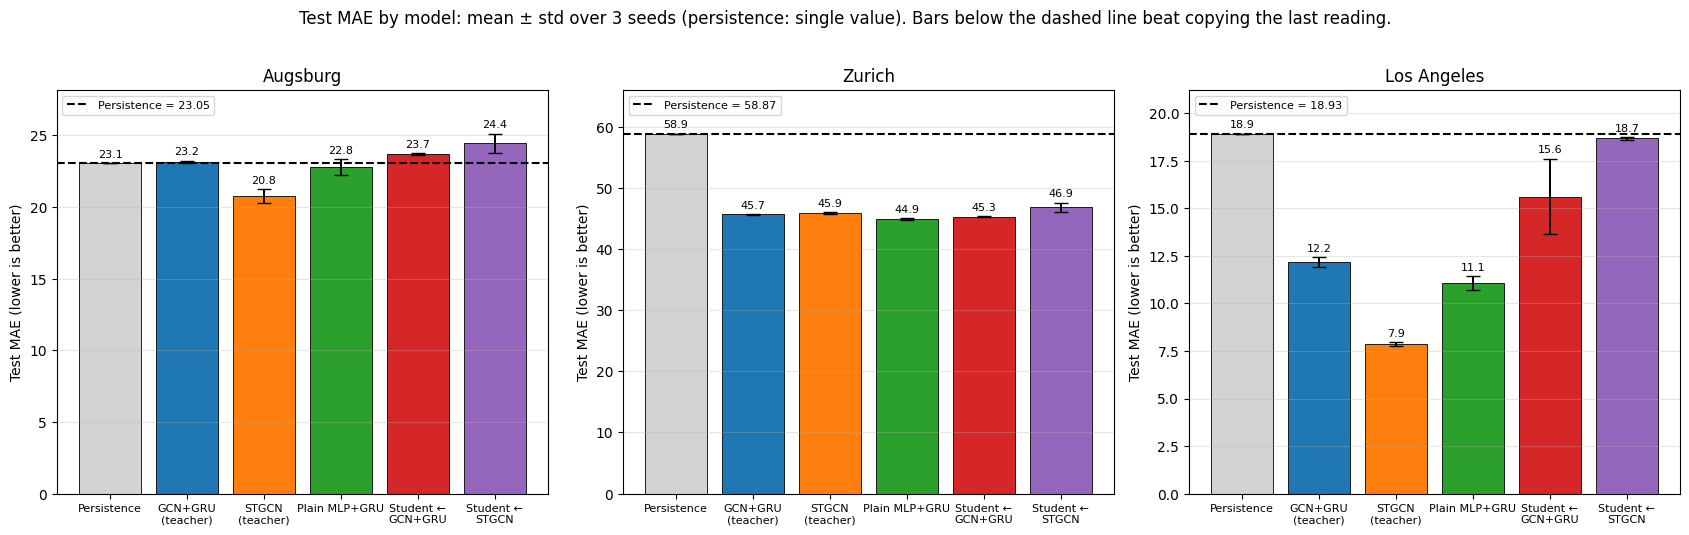

In [6]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "/content/drive/MyDrive/mres_results"
MAIN_DIR = os.path.join(RESULTS_DIR, "main")
CITIES = ["Augsburg", "Zurich", "Los Angeles"]
ORDER = ["GCN+GRU", "STGCN", "Plain MLP", "KD<-GCN+GRU", "KD<-STGCN"]
NAMES = ["Persistence", "GCN+GRU\n(teacher)", "STGCN\n(teacher)", "Plain MLP+GRU", "Student ←\nGCN+GRU", "Student ←\nSTGCN"]
COLORS = ["lightgrey", "tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

recs = [json.load(open(f)) for f in glob.glob(os.path.join(MAIN_DIR, "*.json"))]
df = pd.DataFrame([{"City": r["city"], "Model": r["model"], "Seed": r["seed"],
                    "MAE": r["observed"]["mae"]} for r in recs])
print(df.groupby(["City", "Model"]).size().unstack())      # every cell should be 3

pb = json.load(open(os.path.join(RESULTS_DIR, "persistence_baseline.json")))
persist = {c: pb[c].get("MAE", pb[c].get("mae")) for c in CITIES}

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))          # separate y-axis per city
for ax, city in zip(axes, CITIES):
    g = df[df.City == city]; pers = persist[city]
    means = [pers] + [g[g.Model == m].MAE.mean() for m in ORDER]
    stds = [0.0] + [g[g.Model == m].MAE.std(ddof=1) for m in ORDER]
    ax.bar(range(6), means, yerr=stds, capsize=5, color=COLORS, edgecolor="black",
           linewidth=0.6, error_kw={"elinewidth": 1.4})
    ax.axhline(pers, color="black", ls="--", lw=1.5, label=f"Persistence = {pers:.2f}")
    for i, (m, s) in enumerate(zip(means, stds)):
        ax.text(i, m + s + 0.01 * max(means), f"{m:.1f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(6)); ax.set_xticklabels(NAMES, fontsize=8)
    ax.set_title(city); ax.set_ylabel("Test MAE (lower is better)")
    ax.set_ylim(0, max(m + s for m, s in zip(means, stds)) * 1.12)
    ax.grid(axis="y", alpha=0.3); ax.legend(loc="upper left", fontsize=8)

plt.suptitle("Test MAE by model: mean ± std over 3 seeds (persistence: single value). "
             "Bars below the dashed line beat copying the last reading.", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "fig_mae_grouped.png"), dpi=300, bbox_inches="tight")
plt.show()

Values used (test MAE, seed 42). Order: ['Main (10, 1)', 'Output only (10, 0)', 'Embedding only (0, 1)', 'Medium (1.0, 0.1)', 'Small (0.1, 0.01)']


,"Main (10, 1)","Output only (10, 0)","Embedding only (0, 1)","Medium (1.0, 0.1)","Small (0.1, 0.01)"
Augsburg | Student ← GCN+GRU,23.63,23.03,23.30,23.18,23.12
Augsburg | Student ← STGCN,23.97,23.39,23.08,23.42,22.92
Los Angeles | Student ← GCN+GRU,17.92,13.17,18.11,17.55,14.39
Los Angeles | Student ← STGCN,18.61,12.53,18.24,17.77,16.21


Teacher means: {'Augsburg GCN+GRU': np.float64(23.16), 'Augsburg STGCN': np.float64(20.78), 'Los Angeles GCN+GRU': np.float64(12.17), 'Los Angeles STGCN': np.float64(7.86)}
Persistence: {'Augsburg': 23.05, 'Los Angeles': 18.93}


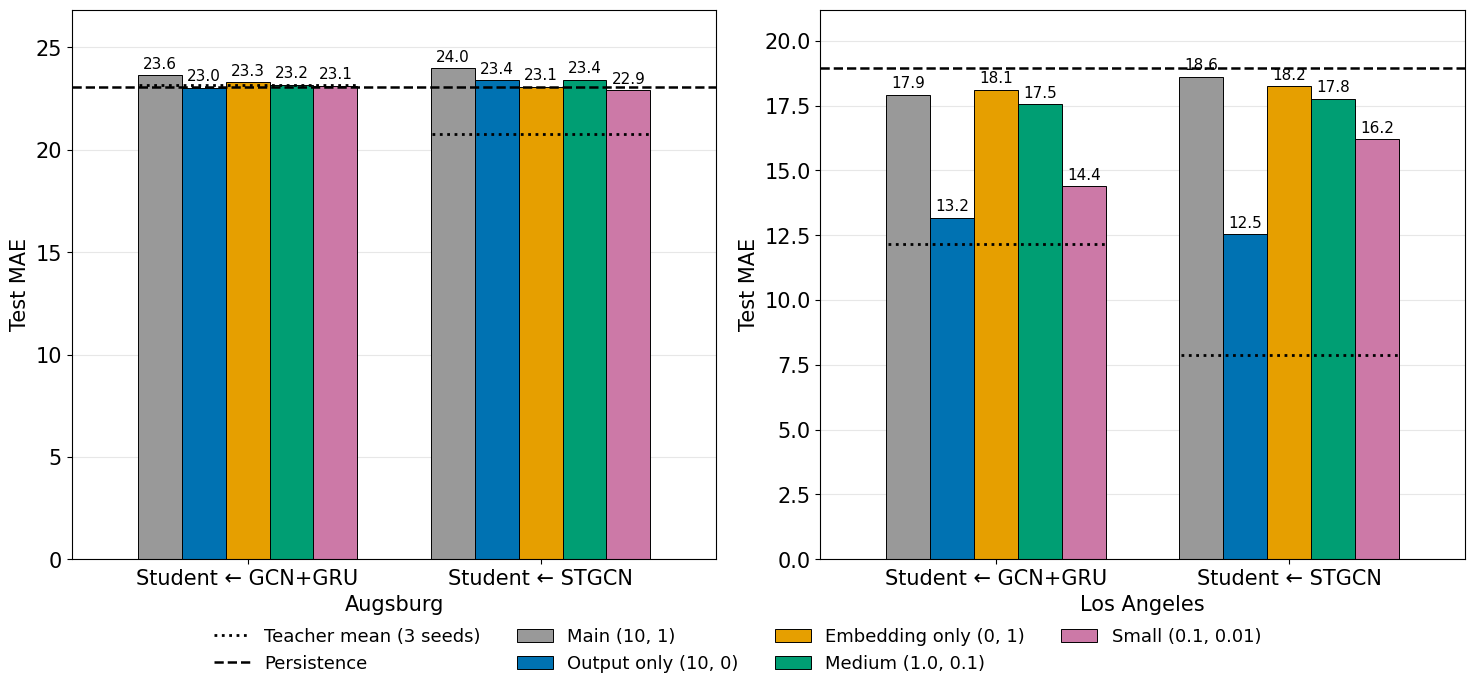

In [9]:
import glob
FIG_DIR = os.path.join(RESULTS_DIR, "figures"); os.makedirs(FIG_DIR, exist_ok=True)
SENS_DIR = os.path.join(RESULTS_DIR, "sensitivity")

SETTINGS = ["Main (10, 1)", "Output only (10, 0)", "Embedding only (0, 1)", "Medium (1.0, 0.1)", "Small (0.1, 0.01)"]
FILE_KEY = {"Output only (10, 0)": "KL only", "Embedding only (0, 1)": "Embedding only",
            "Medium (1.0, 0.1)": "Medium", "Small (0.1, 0.01)": "Small"}
STUDENTS = [("KD<-GCN+GRU", "GCN+GRU"), ("KD<-STGCN", "STGCN")]
P_CITIES = ["Augsburg", "Los Angeles"]

sens = {}
for f in glob.glob(os.path.join(SENS_DIR, "*.json")):
    r = json.load(open(f))
    sens[(r["city"], r["teacher"], r["variant"].split(" (")[0])] = r["mae"]

recs = [json.load(open(f)) for f in glob.glob(os.path.join(MAIN_DIR, "*.json"))]
mdf = pd.DataFrame([{"City": r["city"], "Model": r["model"], "MAE": r["observed"]["mae"]} for r in recs])
teacher_mean = {(c, t): mdf[(mdf.City == c) & (mdf.Model == t)].MAE.mean() for c in P_CITIES for _, t in STUDENTS}

vals = {}
for c in P_CITIES:
    for s, t in STUDENTS:
        row = [json.load(open(mpaths(c, s, 42)[0]))["observed"]["mae"]]
        row += [sens[(c, t, FILE_KEY[k])] for k in SETTINGS[1:]]
        vals[(c, s)] = row

print("Values used (test MAE, seed 42). Order:", SETTINGS)
display(pd.DataFrame({f"{c} | {dn(s)}": v for (c, s), v in vals.items()}, index=SETTINGS).T.round(2))
print("Teacher means:", {f"{c} {t}": round(v, 2) for (c, t), v in teacher_mean.items()})
print("Persistence:", {c: round(baseline[c]["MAE"], 2) for c in P_CITIES})

COL = ["#999999", "#0072B2", "#E69F00", "#009E73", "#CC79A7"]
plt.rcParams.update({"font.size": 15})
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
w = 0.15
for ax, c in zip(axes, P_CITIES):
    top = baseline[c]["MAE"]
    for g, (s, t) in enumerate(STUDENTS):
        for i, k in enumerate(SETTINGS):
            x = g + (i - 2) * w; v = vals[(c, s)][i]; top = max(top, v)
            ax.bar(x, v, w, color=COL[i], edgecolor="black", linewidth=0.7, label=k if g == 0 else None)
            ax.text(x, v + 0.008 * top, f"{v:.1f}", ha="center", va="bottom", fontsize=11)
        ax.hlines(teacher_mean[(c, t)], g - 0.37, g + 0.37, colors="black", ls=":", lw=2,
                  label="Teacher mean (3 seeds)" if g == 0 else None)
    ax.axhline(baseline[c]["MAE"], color="black", ls="--", lw=1.8, label="Persistence")
    ax.set_xticks([0, 1]); ax.set_xticklabels([dn(s) for s, _ in STUDENTS])
    ax.set_xlim(-0.6, 1.6); ax.set_ylim(0, top * 1.12)
    ax.set_ylabel("Test MAE"); ax.set_xlabel(c); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, frameon=False, fontsize=13, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig_sensitivity.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "fig_sensitivity.pdf"), bbox_inches="tight")
plt.show()

End-to-end p95 latency, batch 1 (ms), seed-42 weights:


,Augsburg,Zurich,Los Angeles
GCN+GRU,18.26,17.75,14.27
STGCN,19.08,22.51,26.41
Plain MLP+GRU,0.89,1.03,1.60
Student ← GCN+GRU,1.09,1.06,1.34
Student ← STGCN,1.20,0.88,1.00


Retraining time (s, mean over 3 seeds, teacher included for students):


,Augsburg,Zurich,Los Angeles
GCN+GRU,92.3,86.4,127.9
STGCN,147.6,139.9,260.1
Plain MLP+GRU,54.3,61.4,122.7
Student ← GCN+GRU,204.6,203.6,384.1
Student ← STGCN,285.3,280.1,564.7


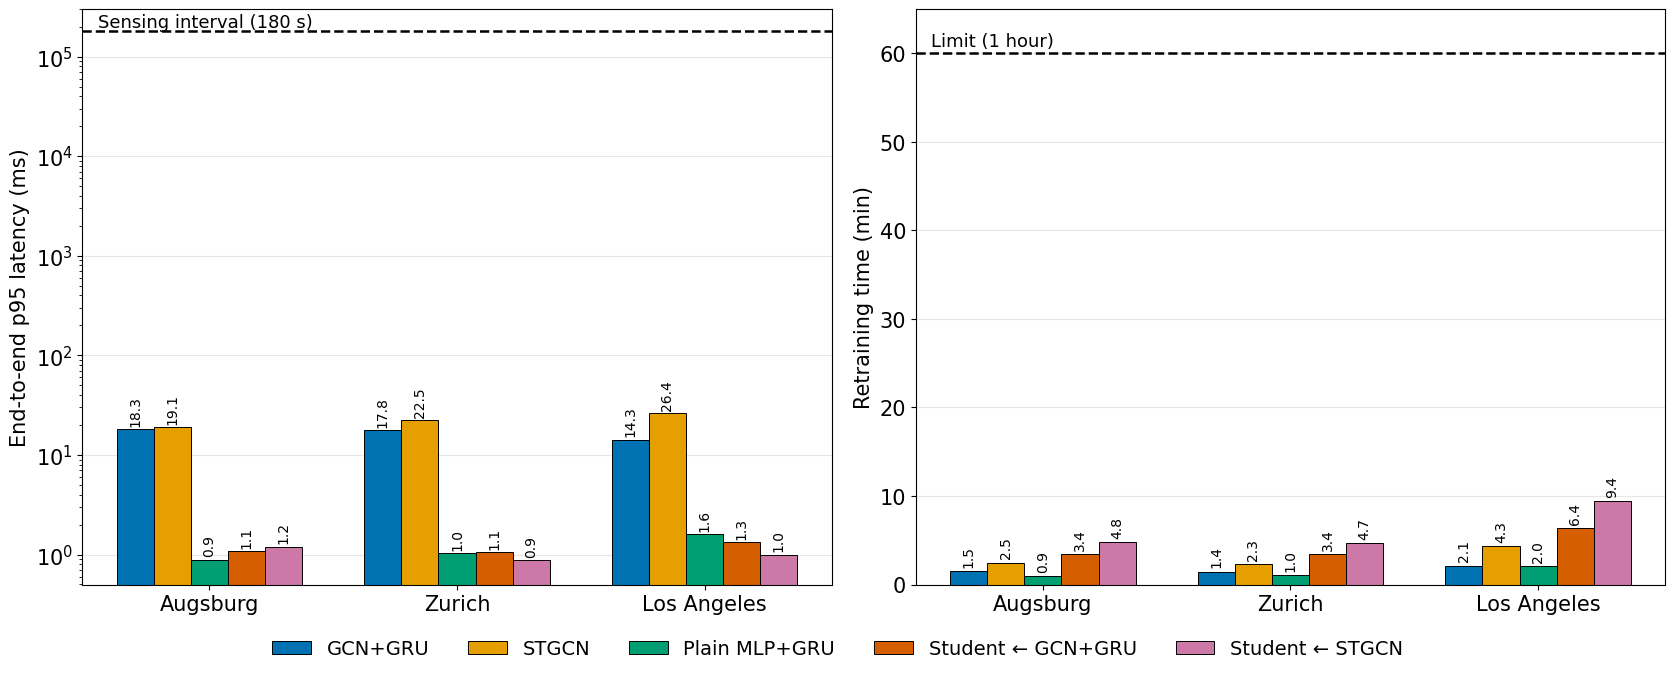

In [9]:
import glob
FIG_DIR = os.path.join(RESULTS_DIR, "figures"); os.makedirs(FIG_DIR, exist_ok=True)
SPEED_DIR = os.path.join(RESULTS_DIR, "speed")
ALL = ["GCN+GRU", "STGCN", "Plain MLP", "KD<-GCN+GRU", "KD<-STGCN"]
COL = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7"]

p95 = {}
for c in CITIES:
    r = json.load(open(os.path.join(SPEED_DIR, f"{CITIES[c]['folder']}_cuda.json")))["speed"]
    for m in ALL: p95[(m, c)] = r[m]["end_to_end"]["1"]["p95_ms"]

recs = [json.load(open(f)) for f in glob.glob(os.path.join(MAIN_DIR, "*.json"))]
tdf = pd.DataFrame([{"City": r["city"], "Model": r["model"],
                     "s": r["train_time_s"] + r.get("teacher_train_time_s", 0.0)} for r in recs])
rt = {(m, c): tdf[(tdf.City == c) & (tdf.Model == m)].s.mean() for m in ALL for c in CITIES}

print("End-to-end p95 latency, batch 1 (ms), seed-42 weights:")
display(pd.DataFrame({c: {dn(m): round(p95[(m, c)], 2) for m in ALL} for c in CITIES}))
print("Retraining time (s, mean over 3 seeds, teacher included for students):")
display(pd.DataFrame({c: {dn(m): round(rt[(m, c)], 1) for m in ALL} for c in CITIES}))

plt.rcParams.update({"font.size": 15})
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 6.5))
w, x = 0.15, np.arange(len(CITIES))
for i, m in enumerate(ALL):
    off = (i - 2) * w
    v1 = [p95[(m, c)] for c in CITIES]; v2 = [rt[(m, c)] / 60 for c in CITIES]
    a1.bar(x + off, v1, w, color=COL[i], edgecolor="black", linewidth=0.7, label=dn(m))
    a2.bar(x + off, v2, w, color=COL[i], edgecolor="black", linewidth=0.7)
    for xi, v in zip(x + off, v1): a1.text(xi, v * 1.15, f"{v:.1f}", ha="center", fontsize=10, rotation=90)
    for xi, v in zip(x + off, v2): a2.text(xi, v + 0.8, f"{v:.1f}", ha="center", fontsize=10, rotation=90)

a1.set_yscale("log"); a1.set_ylim(0.5, 3e5)
a1.axhline(180000, color="black", ls="--", lw=1.8)
a1.text(-0.45, 180000 * 1.1, "Sensing interval (180 s)", fontsize=13)
a2.set_ylim(0, 65); a2.axhline(60, color="black", ls="--", lw=1.8)
a2.text(-0.45, 60.8, "Limit (1 hour)", fontsize=13)
for a, yl in [(a1, "End-to-end p95 latency (ms)"), (a2, "Retraining time (min)")]:
    a.set_xticks(x); a.set_xticklabels(CITIES); a.set_ylabel(yl)
    a.grid(axis="y", alpha=0.3); a.set_axisbelow(True)
h, l = a1.get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=5, frameon=False, fontsize=14, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig_latency_retraining.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "fig_latency_retraining.pdf"), bbox_inches="tight")
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


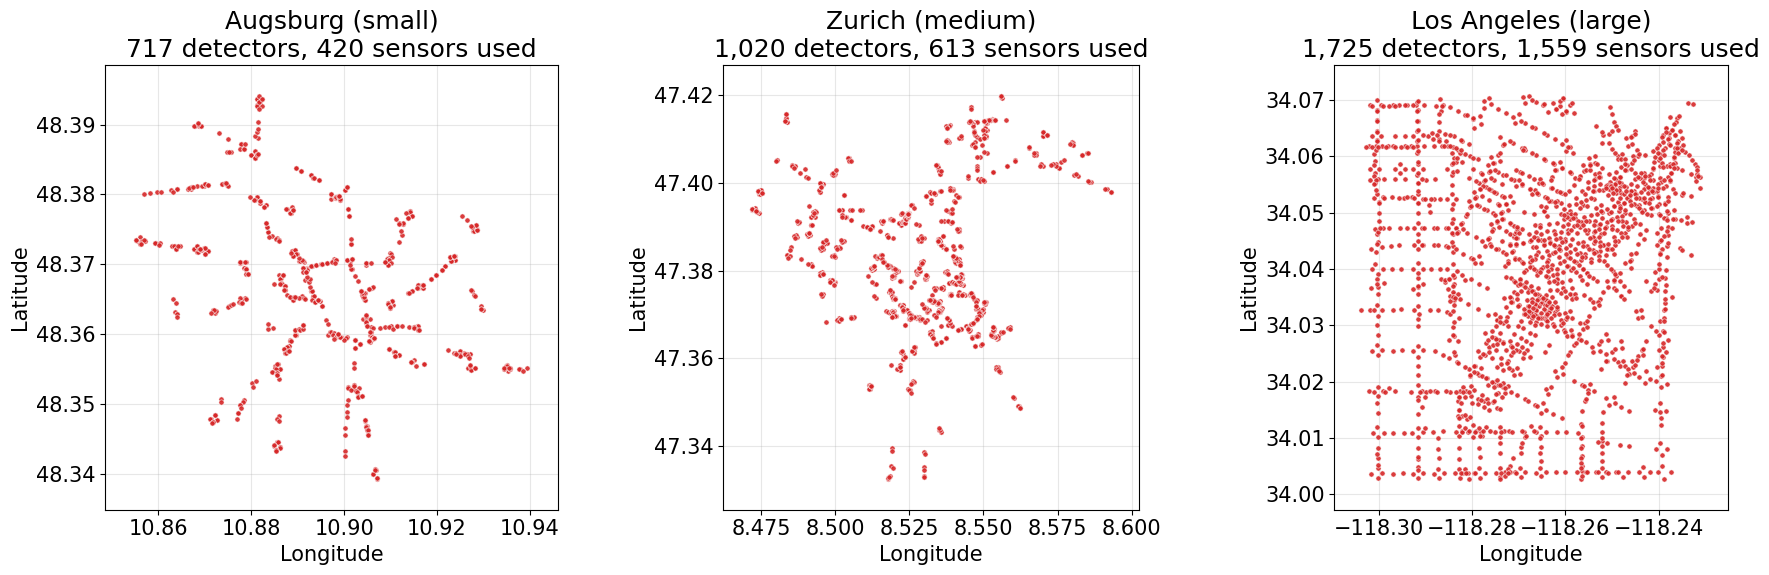

In [11]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "/content/drive/MyDrive"
FIG_DIR = "/content/drive/MyDrive/mres_results/figures"; os.makedirs(FIG_DIR, exist_ok=True)
CITIES = {"Augsburg": ("augsburg", "small", 420),
          "Zurich": ("zurich", "medium", 613),
          "Los Angeles": ("losangeles", "large", 1559)}   # folder, size, sensors used

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (name, (c, size, n_sensors)) in zip(axes, CITIES.items()):
    det = pd.read_parquet(os.path.join(DATA_DIR, c, "sensors", "detectors_info.parquet"))
    ax.scatter(det["long"], det["lat"], s=14, c="#d62728", edgecolors="white",
               linewidths=0.4, alpha=0.9, zorder=3)
    pad_x = 0.08 * (det["long"].max() - det["long"].min())
    pad_y = 0.08 * (det["lat"].max() - det["lat"].min())
    ax.set_xlim(det["long"].min() - pad_x, det["long"].max() + pad_x)
    ax.set_ylim(det["lat"].min() - pad_y, det["lat"].max() + pad_y)
    ax.set_aspect(1 / np.cos(np.radians(det["lat"].mean())))
    ax.set_title(f"{name} ({size})\n{len(det):,} detectors, {n_sensors:,} sensors used")
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.grid(alpha=0.3)
    ax.ticklabel_format(useOffset=False, style="plain")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig_detector_maps.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "fig_detector_maps.pdf"), bbox_inches="tight")
plt.show()